In [1]:
# P3: Supply Chain Demand Forecasting
# Environment setup

import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("P3 environment ready!")

Python: 3.13.16
Pandas: 2.2.3
Scikit-learn: 1.6.1
PyTorch: 2.11.0+cpu
GPU available: False
P3 environment ready!


In [2]:
# P3: Generate synthetic supply-chain demand data

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

n_days = 365
n_skus = 12

dates = pd.date_range("2025-01-01", periods=n_days, freq="D")
categories = ["Electronics", "Fashion", "Home", "Grocery"]

records = []

sku_info = {
    f"SKU_{i:03d}": {
        "category": categories[i % len(categories)],
        "base_demand": rng.integers(20, 120),
        "region": f"Region_{i % 4 + 1}"
    }
    for i in range(1, n_skus + 1)
}

for sku, info in sku_info.items():
    for day_index, date in enumerate(dates):
        seasonal = 1 + 0.20 * np.sin(2 * np.pi * day_index / 365)
        weekend = 1.15 if date.dayofweek >= 5 else 1.0

        discount = float(rng.choice([0, 5, 10, 15, 20, 25]))
        regional_index = float(rng.uniform(0.8, 1.2))
        shipping_delay_days = int(rng.integers(0, 6))

        demand = (
            info["base_demand"]
            * seasonal
            * weekend
            * (1 + discount / 100 * 0.8)
            * regional_index
            * (1 - 0.025 * shipping_delay_days)
            + rng.normal(0, 8)
        )

        records.append({
            "date": date,
            "sku": sku,
            "category": info["category"],
            "region": info["region"],
            "promotion_discount_pct": discount,
            "regional_demand_index": regional_index,
            "shipping_delay_days": shipping_delay_days,
            "day_of_week": date.dayofweek,
            "day_of_year": date.dayofyear,
            "daily_order_volume": max(0, int(round(demand)))
        })

demand_df = pd.DataFrame(records)
demand_df.to_csv("p3_supply_chain_demand.csv", index=False)

print("Dataset shape:", demand_df.shape)
print("Date range:", demand_df["date"].min(), "to", demand_df["date"].max())
print("Unique SKUs:", demand_df["sku"].nunique())
print("\nSample records:")
display(demand_df.head())
print("\nMissing values:", demand_df.isna().sum().sum())
print("\nSaved: p3_supply_chain_demand.csv")

Dataset shape: (4380, 10)
Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00
Unique SKUs: 12

Sample records:


,date,sku,category,region,promotion_discount_pct,regional_demand_index,shipping_delay_days,day_of_week,day_of_year,daily_order_volume
0,2025-01-01,SKU_001,Fashion,Region_2,20.0,1.114426,4,2,1,32
1,2025-01-02,SKU_001,Fashion,Region_2,25.0,0.948319,2,3,2,37
2,2025-01-03,SKU_001,Fashion,Region_2,20.0,1.129105,3,4,3,38
3,2025-01-04,SKU_001,Fashion,Region_2,10.0,1.021834,1,5,4,27
4,2025-01-05,SKU_001,Fashion,Region_2,25.0,1.052666,4,6,5,36



Missing values: 0

Saved: p3_supply_chain_demand.csv


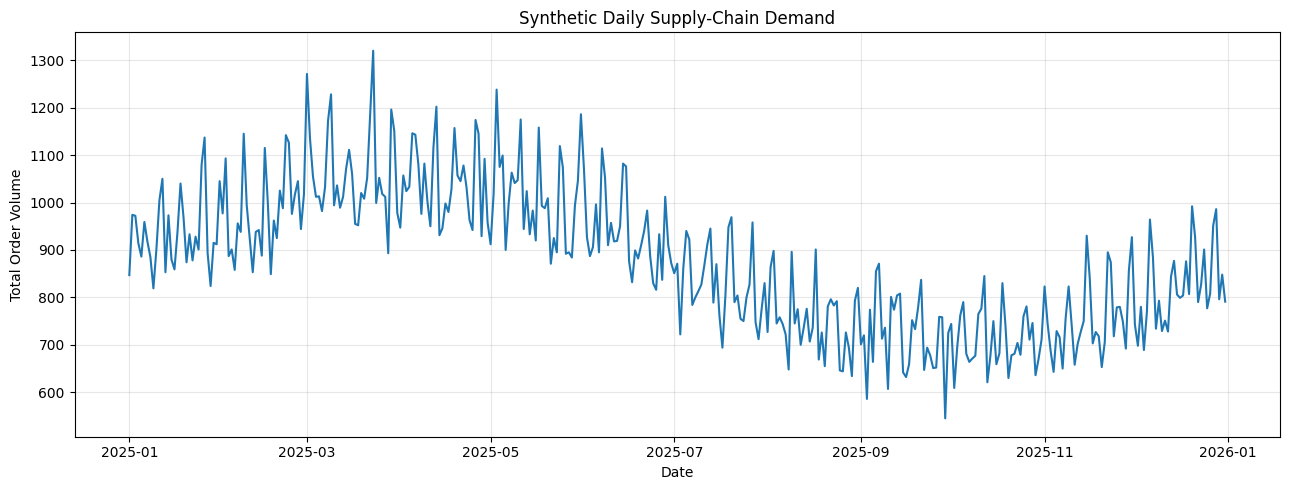

,mean,median,std,min,max
category,,,,,
Electronics,96.06,91.0,32.36,34,214
Fashion,47.21,43.0,20.54,0,117
Grocery,66.96,69.0,31.95,3,171
Home,82.59,90.0,42.30,5,189


In [3]:
import matplotlib.pyplot as plt

daily_total = demand_df.groupby("date")["daily_order_volume"].sum()

plt.figure(figsize=(13, 5))
plt.plot(daily_total.index, daily_total.values)
plt.title("Synthetic Daily Supply-Chain Demand")
plt.xlabel("Date")
plt.ylabel("Total Order Volume")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("p3_daily_demand_overview.png", dpi=150)
plt.show()

display(
    demand_df.groupby("category")["daily_order_volume"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Sort chronologically
demand_df["date"] = pd.to_datetime(demand_df["date"])
demand_df = demand_df.sort_values("date").reset_index(drop=True)

# Time-based features and categorical encoding
feature_cols = [
    "sku",
    "category",
    "region",
    "promotion_discount_pct",
    "regional_demand_index",
    "shipping_delay_days",
    "day_of_week",
    "day_of_year",
]

X_all = pd.get_dummies(
    demand_df[feature_cols],
    columns=["sku", "category", "region"],
    dtype=float
)

y_all = demand_df["daily_order_volume"].astype(float)

# Chronological 80/20 split
split_idx = int(len(demand_df) * 0.8)

X_train = X_all.iloc[:split_idx].copy()
X_test = X_all.iloc[split_idx:].copy()
y_train = y_all.iloc[:split_idx].copy()
y_test = y_all.iloc[split_idx:].copy()

# Scale numerical features using training data only
numeric_cols = [
    "promotion_discount_pct",
    "regional_demand_index",
    "shipping_delay_days",
    "day_of_week",
    "day_of_year",
]

scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Feature preparation complete")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Number of features:", X_train.shape[1])
print("Training dates:", demand_df["date"].iloc[0], "to",
      demand_df["date"].iloc[split_idx - 1])
print("Testing dates:", demand_df["date"].iloc[split_idx], "to",
      demand_df["date"].iloc[-1])
print("Missing values in features:", X_all.isna().sum().sum())

Feature preparation complete
Training rows: 3504
Testing rows: 876
Number of features: 25
Training dates: 2025-01-01 00:00:00 to 2025-10-19 00:00:00
Testing dates: 2025-10-20 00:00:00 to 2025-12-31 00:00:00
Missing values in features: 0


In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Train baseline model
rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

# Evaluate
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

rf_results = pd.DataFrame([{
    "Model": "Random Forest Baseline",
    "MAE": rf_mae,
    "RMSE": rf_rmse,
    "R2": rf_r2
}])

display(rf_results.round(4))

print("Random Forest baseline training complete.")

,Model,MAE,RMSE,R2
0,Random Forest Baseline,9.1715,11.6492,0.8645


Random Forest baseline training complete.


In [6]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Convert prepared features to PyTorch tensors
Xtr = torch.tensor(X_train.to_numpy(dtype=np.float32))
Xte = torch.tensor(X_test.to_numpy(dtype=np.float32))
ytr = torch.tensor(y_train.to_numpy(dtype=np.float32).reshape(-1, 1))
yte = torch.tensor(y_test.to_numpy(dtype=np.float32).reshape(-1, 1))

train_loader = DataLoader(
    TensorDataset(Xtr, ytr),
    batch_size=64,
    shuffle=True
)

class DemandMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, dropout=0.2):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1)
        )

    def forward(self, x):
        return self.network(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
mlp_model = DemandMLP(
    input_dim=Xtr.shape[1],
    hidden_dim=64,
    dropout=0.2
).to(device)

optimizer = torch.optim.Adam(
    mlp_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)
loss_fn = nn.MSELoss()

# Reserve the last part of training dates for validation
val_size = int(len(Xtr) * 0.15)
fit_size = len(Xtr) - val_size

fit_dataset = TensorDataset(Xtr[:fit_size], ytr[:fit_size])
fit_loader = DataLoader(fit_dataset, batch_size=64, shuffle=True)

Xval = Xtr[fit_size:].to(device)
yval = ytr[fit_size:].to(device)

history = {"train_loss": [], "val_loss": []}
epochs = 40

for epoch in range(epochs):
    mlp_model.train()
    train_losses = []

    for xb, yb in fit_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        predictions = mlp_model(xb)
        loss = loss_fn(predictions, yb)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    mlp_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(mlp_model(Xval), yval).item()

    history["train_loss"].append(float(np.mean(train_losses)))
    history["val_loss"].append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train MSE: {history['train_loss'][-1]:.3f} | "
            f"Validation MSE: {val_loss:.3f}"
        )

# Evaluate once on the untouched chronological test set
mlp_model.eval()
with torch.no_grad():
    mlp_predictions = mlp_model(Xte.to(device)).cpu().numpy().ravel()

mlp_mae = mean_absolute_error(y_test, mlp_predictions)
mlp_rmse = np.sqrt(mean_squared_error(y_test, mlp_predictions))
mlp_r2 = r2_score(y_test, mlp_predictions)

print("\nMLP test metrics")
print(f"MAE:  {mlp_mae:.4f}")
print(f"RMSE: {mlp_rmse:.4f}")
print(f"R²:   {mlp_r2:.4f}")

Epoch 10/40 | Train MSE: 4469.935 | Validation MSE: 2690.954
Epoch 20/40 | Train MSE: 896.806 | Validation MSE: 650.474
Epoch 30/40 | Train MSE: 239.311 | Validation MSE: 171.237
Epoch 40/40 | Train MSE: 206.435 | Validation MSE: 121.682

MLP test metrics
MAE:  25.1149
RMSE: 29.9990
R²:   0.1015


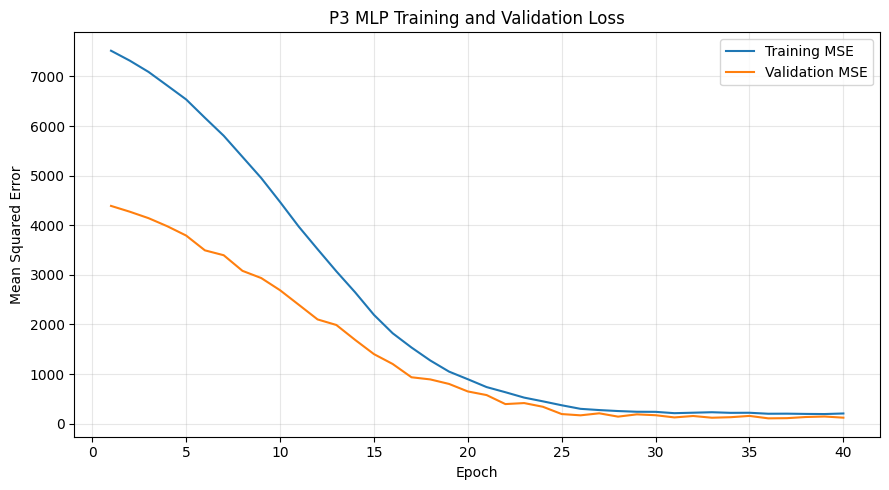

Saved: p3_mlp_validation_loss.png


In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(history["train_loss"]) + 1),
    history["train_loss"],
    label="Training MSE"
)
plt.plot(
    range(1, len(history["val_loss"]) + 1),
    history["val_loss"],
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("P3 MLP Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("p3_mlp_validation_loss.png", dpi=150)
plt.show()

print("Saved: p3_mlp_validation_loss.png")

In [8]:
import numpy as np
import pandas as pd

# Work from the original generated dataset
forecast_df = demand_df.copy()
forecast_df["date"] = pd.to_datetime(forecast_df["date"])
forecast_df = forecast_df.sort_values(["sku", "date"]).reset_index(drop=True)

# Historical demand features per SKU
forecast_df["lag_1"] = (
    forecast_df.groupby("sku")["daily_order_volume"].shift(1)
)

forecast_df["lag_7"] = (
    forecast_df.groupby("sku")["daily_order_volume"].shift(7)
)

# Shift first, then roll, so the current day's target is excluded
forecast_df["rolling_mean_7"] = (
    forecast_df.groupby("sku")["daily_order_volume"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

forecast_df = forecast_df.dropna().reset_index(drop=True)

print("Forecasting dataset shape:", forecast_df.shape)
display(
    forecast_df[
        ["date", "sku", "daily_order_volume",
         "lag_1", "lag_7", "rolling_mean_7"]
    ].head(10)
)

Forecasting dataset shape: (4296, 13)


,date,sku,daily_order_volume,lag_1,lag_7,rolling_mean_7
0,2025-01-08,SKU_001,30,30.0,32.0,33.714286
1,2025-01-09,SKU_001,33,30.0,37.0,33.428571
2,2025-01-10,SKU_001,42,33.0,38.0,32.857143
3,2025-01-11,SKU_001,29,42.0,27.0,33.428571
4,2025-01-12,SKU_001,37,29.0,36.0,33.714286
5,2025-01-13,SKU_001,35,37.0,36.0,33.857143
6,2025-01-14,SKU_001,39,35.0,30.0,33.714286
7,2025-01-15,SKU_001,29,39.0,30.0,35.000000
8,2025-01-16,SKU_001,32,29.0,33.0,34.857143
9,2025-01-17,SKU_001,30,32.0,42.0,34.714286


In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Chronological split: use the first 80% of dates for training
forecast_df = forecast_df.sort_values("date").reset_index(drop=True)
split_date = forecast_df["date"].sort_values().iloc[
    int(len(forecast_df) * 0.8)
]

train_df = forecast_df[forecast_df["date"] < split_date].copy()
test_df = forecast_df[forecast_df["date"] >= split_date].copy()

feature_cols = [
    "sku", "category", "region",
    "promotion_discount_pct", "regional_demand_index",
    "shipping_delay_days", "day_of_week", "day_of_year",
    "lag_1", "lag_7", "rolling_mean_7"
]

X_train_new = pd.get_dummies(
    train_df[feature_cols],
    columns=["sku", "category", "region"],
    dtype=float
)

X_test_new = pd.get_dummies(
    test_df[feature_cols],
    columns=["sku", "category", "region"],
    dtype=float
).reindex(columns=X_train_new.columns, fill_value=0)

y_train_new = train_df["daily_order_volume"].astype(float)
y_test_new = test_df["daily_order_volume"].astype(float)

print("Train:", X_train_new.shape, train_df["date"].min(), "to", train_df["date"].max())
print("Test: ", X_test_new.shape, test_df["date"].min(), "to", test_df["date"].max())

# Random Forest baseline with lag features
rf_lag_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_lag_model.fit(X_train_new, y_train_new)
rf_lag_pred = rf_lag_model.predict(X_test_new)

print("\nRandom Forest with lag features")
print("MAE:", round(mean_absolute_error(y_test_new, rf_lag_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_new, rf_lag_pred)), 4))
print("R²:", round(r2_score(y_test_new, rf_lag_pred), 4))

Train: (3432, 28) 2025-01-08 00:00:00 to 2025-10-20 00:00:00
Test:  (864, 28) 2025-10-21 00:00:00 to 2025-12-31 00:00:00

Random Forest with lag features
MAE: 7.9402
RMSE: 9.9268
R²: 0.9019


In [10]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Scale using training data only
scaler_new = StandardScaler()
Xtr_new = scaler_new.fit_transform(X_train_new).astype(np.float32)
Xte_new = scaler_new.transform(X_test_new).astype(np.float32)

# Scale target for more stable neural-network training
y_mean = float(y_train_new.mean())
y_std = float(y_train_new.std())

ytr_scaled = ((y_train_new.to_numpy() - y_mean) / y_std).astype(np.float32)

Xtr_t = torch.tensor(Xtr_new)
ytr_t = torch.tensor(ytr_scaled.reshape(-1, 1))
Xte_t = torch.tensor(Xte_new).to(device)

# Last 15% of training rows for validation
val_size = int(len(Xtr_t) * 0.15)
fit_size = len(Xtr_t) - val_size

fit_ds = TensorDataset(Xtr_t[:fit_size], ytr_t[:fit_size])
fit_loader = DataLoader(fit_ds, batch_size=64, shuffle=True)

Xval_t = Xtr_t[fit_size:].to(device)
yval_t = ytr_t[fit_size:].to(device)

class ImprovedDemandMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1)
        )

    def forward(self, x):
        return self.net(x)

mlp_lag_model = ImprovedDemandMLP(
    input_dim=Xtr_new.shape[1],
    hidden_dim=64,
    dropout=0.2
).to(device)

optimizer = torch.optim.Adam(
    mlp_lag_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)
loss_fn = nn.MSELoss()

history_new = {"train_loss": [], "val_loss": []}
epochs = 60

for epoch in range(epochs):
    mlp_lag_model.train()
    batch_losses = []

    for xb, yb in fit_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(mlp_lag_model(xb), yb)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

    mlp_lag_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(
            mlp_lag_model(Xval_t), yval_t
        ).item()

    history_new["train_loss"].append(float(np.mean(batch_losses)))
    history_new["val_loss"].append(float(val_loss))

    if (epoch + 1) % 15 == 0:
        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train loss: {np.mean(batch_losses):.4f} | "
            f"Validation loss: {val_loss:.4f}"
        )

# Predict and reverse target scaling
mlp_lag_model.eval()
with torch.no_grad():
    pred_scaled = mlp_lag_model(Xte_t).cpu().numpy().ravel()

mlp_lag_pred = pred_scaled * y_std + y_mean

print("\nImproved MLP test results")
print("MAE:", round(mean_absolute_error(y_test_new, mlp_lag_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_new, mlp_lag_pred)), 4))
print("R²:", round(r2_score(y_test_new, mlp_lag_pred), 4))

Epoch 15/60 | Train loss: 0.1113 | Validation loss: 0.0640
Epoch 30/60 | Train loss: 0.1002 | Validation loss: 0.0596
Epoch 45/60 | Train loss: 0.1003 | Validation loss: 0.0560
Epoch 60/60 | Train loss: 0.0941 | Validation loss: 0.0610

Improved MLP test results
MAE: 14.0518
RMSE: 17.381
R²: 0.6993


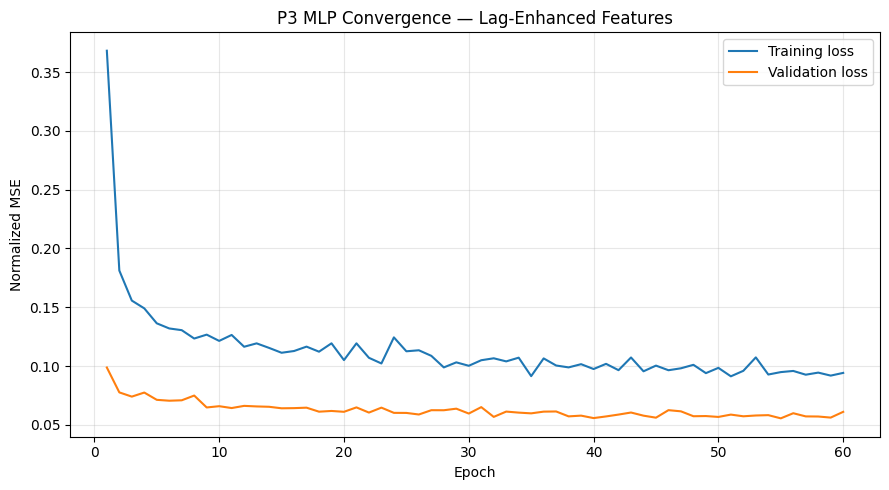

Best validation-loss epoch: 55
Best validation loss: 0.05548


In [11]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, len(history_new["train_loss"]) + 1),
    history_new["train_loss"],
    label="Training loss"
)
plt.plot(
    np.arange(1, len(history_new["val_loss"]) + 1),
    history_new["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Normalized MSE")
plt.title("P3 MLP Convergence — Lag-Enhanced Features")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("p3_mlp_convergence.png", dpi=150)
plt.show()

best_epoch = int(np.argmin(history_new["val_loss"])) + 1
print("Best validation-loss epoch:", best_epoch)
print("Best validation loss:", round(min(history_new["val_loss"]), 5))

In [12]:
import copy
import itertools
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Uses the scaled training data and chronological validation split
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

search_space = list(itertools.product(
    [32, 64, 96],       # hidden dimensions
    [0.1, 0.2, 0.3],    # dropout
    [0.001, 0.0003],    # learning rate
    [1e-4, 1e-3]        # L2 weight decay
))

rng = np.random.default_rng(42)
selected_indices = rng.choice(
    len(search_space), size=8, replace=False
)
candidates = [search_space[i] for i in selected_indices]

# Keep the same chronological fit/validation boundary
fit_X = Xtr_t[:fit_size]
fit_y = ytr_t[:fit_size]
val_X = Xtr_t[fit_size:].to(device)
val_y = ytr_t[fit_size:].to(device)

search_results = []
best_state = None
best_config = None
best_val_loss = float("inf")

for trial, (hidden_dim, dropout, lr, weight_decay) in enumerate(
    candidates, start=1
):
    torch.manual_seed(42)

    model = ImprovedDemandMLP(
        input_dim=Xtr_new.shape[1],
        hidden_dim=hidden_dim,
        dropout=dropout
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )
    loss_fn = nn.MSELoss()

    loader = DataLoader(
        TensorDataset(fit_X, fit_y),
        batch_size=64,
        shuffle=True
    )

    trial_best = float("inf")
    trial_best_state = None
    patience = 8
    epochs_without_improvement = 0

    for epoch in range(45):
        model.train()

        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(val_X), val_y).item()

        if val_loss < trial_best:
            trial_best = val_loss
            trial_best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    search_results.append({
        "trial": trial,
        "hidden_dim": hidden_dim,
        "dropout": dropout,
        "learning_rate": lr,
        "weight_decay": weight_decay,
        "best_validation_mse": trial_best,
        "best_epoch": epoch + 1
    })

    print(
        f"Trial {trial}/8 | hidden={hidden_dim}, dropout={dropout}, "
        f"lr={lr}, L2={weight_decay} | "
        f"best validation MSE={trial_best:.5f}"
    )

    if trial_best < best_val_loss:
        best_val_loss = trial_best
        best_config = (hidden_dim, dropout, lr, weight_decay)
        best_state = trial_best_state

search_df = pd.DataFrame(search_results).sort_values(
    "best_validation_mse"
).reset_index(drop=True)

print("\nBest configuration:", best_config)
print("Best validation MSE:", round(best_val_loss, 5))
display(search_df)

Trial 1/8 | hidden=32, dropout=0.1, lr=0.0003, L2=0.001 | best validation MSE=0.06967
Trial 2/8 | hidden=96, dropout=0.1, lr=0.001, L2=0.001 | best validation MSE=0.05433
Trial 3/8 | hidden=96, dropout=0.2, lr=0.001, L2=0.001 | best validation MSE=0.05349
Trial 4/8 | hidden=64, dropout=0.3, lr=0.001, L2=0.0001 | best validation MSE=0.05874
Trial 5/8 | hidden=96, dropout=0.3, lr=0.001, L2=0.0001 | best validation MSE=0.05804
Trial 6/8 | hidden=64, dropout=0.1, lr=0.0003, L2=0.0001 | best validation MSE=0.06533
Trial 7/8 | hidden=32, dropout=0.1, lr=0.0003, L2=0.0001 | best validation MSE=0.06950
Trial 8/8 | hidden=64, dropout=0.3, lr=0.0003, L2=0.001 | best validation MSE=0.06770

Best configuration: (96, 0.2, 0.001, 0.001)
Best validation MSE: 0.05349


,trial,hidden_dim,dropout,learning_rate,weight_decay,best_validation_mse,best_epoch
0,3,96,0.2,0.0010,0.0010,0.053490,45
1,2,96,0.1,0.0010,0.0010,0.054335,40
2,5,96,0.3,0.0010,0.0001,0.058038,41
3,4,64,0.3,0.0010,0.0001,0.058740,45
4,6,64,0.1,0.0003,0.0001,0.065328,21
5,8,64,0.3,0.0003,0.0010,0.067695,21
6,7,32,0.1,0.0003,0.0001,0.069505,24
7,1,32,0.1,0.0003,0.0010,0.069666,24


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import torch

# Build the selected architecture
hidden_dim, dropout, lr, weight_decay = best_config

tuned_mlp = ImprovedDemandMLP(
    input_dim=Xtr_new.shape[1],
    hidden_dim=hidden_dim,
    dropout=dropout
).to(device)

tuned_mlp.load_state_dict(best_state)
tuned_mlp.eval()

# Predict on the untouched test set
with torch.no_grad():
    pred_scaled = tuned_mlp(Xte_t).cpu().numpy().ravel()

tuned_predictions = pred_scaled * y_std + y_mean

tuned_metrics = {
    "Model": "Tuned PyTorch MLP",
    "MAE": mean_absolute_error(y_test_new, tuned_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test_new, tuned_predictions)),
    "R2": r2_score(y_test_new, tuned_predictions)
}

rf_metrics = {
    "Model": "Random Forest with lag features",
    "MAE": mean_absolute_error(y_test_new, rf_lag_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test_new, rf_lag_pred)),
    "R2": r2_score(y_test_new, rf_lag_pred)
}

final_comparison = pd.DataFrame([rf_metrics, tuned_metrics])
display(final_comparison.round(4))

final_comparison.to_csv(
    "p3_model_comparison.csv", index=False
)

print("Saved: p3_model_comparison.csv")

,Model,MAE,RMSE,R2
0,Random Forest with lag features,7.9402,9.9268,0.9019
1,Tuned PyTorch MLP,12.3991,15.6092,0.7575


Saved: p3_model_comparison.csv


In [14]:
import os
import json
import joblib
import torch
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("p3_results", exist_ok=True)
os.makedirs("p3_models", exist_ok=True)

# Save tuning results and final comparison
search_df.to_csv(
    "p3_results/p3_hyperparameter_search.csv",
    index=False
)

final_comparison.to_csv(
    "p3_results/p3_model_comparison.csv",
    index=False
)

forecast_df.to_csv(
    "p3_results/p3_forecasting_dataset.csv",
    index=False
)

# Save the best tuned MLP checkpoint
torch.save(
    {
        "model_state_dict": best_state,
        "input_dim": int(Xtr_new.shape[1]),
        "hidden_dim": int(best_config[0]),
        "dropout": float(best_config[1]),
        "learning_rate": float(best_config[2]),
        "weight_decay": float(best_config[3]),
        "target_mean": y_mean,
        "target_std": y_std,
        "feature_columns": list(X_train_new.columns),
    },
    "p3_models/tuned_demand_mlp.pt"
)

joblib.dump(
    rf_lag_model,
    "p3_models/random_forest_demand.joblib"
)

joblib.dump(
    scaler_new,
    "p3_models/demand_feature_scaler.joblib"
)

joblib.dump(
    best_config,
    "p3_models/best_mlp_config.joblib"
)

# Save the convergence plot
plt.figure(figsize=(9, 5))
plt.plot(history_new["train_loss"], label="Training loss")
plt.plot(history_new["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Normalized MSE")
plt.title("P3 MLP Convergence")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("p3_results/p3_mlp_convergence.png", dpi=150)
plt.close()

# Write an evaluation summary
report = {
    "dataset_type": "synthetic",
    "rows_after_lag_features": int(len(forecast_df)),
    "training_rows": int(len(train_df)),
    "testing_rows": int(len(test_df)),
    "best_mlp_configuration": {
        "hidden_dim": int(best_config[0]),
        "dropout": float(best_config[1]),
        "learning_rate": float(best_config[2]),
        "weight_decay": float(best_config[3]),
    },
    "best_validation_mse_normalized": float(best_val_loss),
    "test_metrics": final_comparison.to_dict(orient="records"),
}

with open("p3_results/p3_evaluation_report.json", "w") as f:
    json.dump(report, f, indent=2)

print("P3 artifacts saved.")
print("\nResults:", os.listdir("p3_results"))
print("\nModels:", os.listdir("p3_models"))

P3 artifacts saved.

Results: ['p3_hyperparameter_search.csv', 'p3_forecasting_dataset.csv', 'p3_model_comparison.csv', 'p3_mlp_convergence.png', 'p3_evaluation_report.json']

Models: ['demand_feature_scaler.joblib', 'random_forest_demand.joblib', 'tuned_demand_mlp.pt', 'best_mlp_config.joblib']


In [15]:
import os
import shutil

repo = "/content/ml-genai-enterprise-lab"
p3 = os.path.join(repo, "P3_Supply_Chain_Demand_Forecasting")

os.makedirs(os.path.join(p3, "notebook"), exist_ok=True)
os.makedirs(os.path.join(p3, "models"), exist_ok=True)
os.makedirs(os.path.join(p3, "results"), exist_ok=True)

# Copy saved model artifacts
for name in os.listdir("/content/p3_models"):
    src = os.path.join("/content/p3_models", name)
    if os.path.isfile(src):
        shutil.copy2(src, os.path.join(p3, "models", name))

# Copy result files
for name in os.listdir("/content/p3_results"):
    src = os.path.join("/content/p3_results", name)
    if os.path.isfile(src):
        shutil.copy2(src, os.path.join(p3, "results", name))

# Copy the source dataset and demand chart if present
for name in [
    "p3_supply_chain_demand.csv",
    "p3_daily_demand_overview.png",
    "p3_mlp_validation_loss.png",
]:
    src = os.path.join("/content", name)
    if os.path.isfile(src):
        shutil.copy2(src, os.path.join(p3, "results", name))

print("P3 artifacts copied.")
for root, dirs, files in os.walk(p3):
    for name in files:
        print(os.path.relpath(os.path.join(root, name), repo))


P3 artifacts copied.
P3_Supply_Chain_Demand_Forecasting/results/p3_hyperparameter_search.csv
P3_Supply_Chain_Demand_Forecasting/results/p3_forecasting_dataset.csv
P3_Supply_Chain_Demand_Forecasting/results/p3_model_comparison.csv
P3_Supply_Chain_Demand_Forecasting/results/p3_mlp_convergence.png
P3_Supply_Chain_Demand_Forecasting/results/p3_supply_chain_demand.csv
P3_Supply_Chain_Demand_Forecasting/results/p3_mlp_validation_loss.png
P3_Supply_Chain_Demand_Forecasting/results/p3_daily_demand_overview.png
P3_Supply_Chain_Demand_Forecasting/results/p3_evaluation_report.json
P3_Supply_Chain_Demand_Forecasting/models/demand_feature_scaler.joblib
P3_Supply_Chain_Demand_Forecasting/models/random_forest_demand.joblib
P3_Supply_Chain_Demand_Forecasting/models/tuned_demand_mlp.pt
P3_Supply_Chain_Demand_Forecasting/models/best_mlp_config.joblib
